# Body weight: posterior contrasts

One body-weight measurement per rat, modeled with a Gaussian likelihood and common residual variance. The fitted model uses `body_weight ~ gtyp + age + sex + gtyp:age + gtyp:sex`, without a rat random intercept. All effects are expressed in the original body-weight units (typically grams).

Genotype, age and sex effects are averaged equally over the other factor levels. There are no Vehicle/Empa comparisons because body weight was measured only once per rat.

In [3]:
import arviz as az
import pandas as pd
import matplotlib.pyplot as plt

from kidney.paths import RESULTS_DIR, PLOT_DIR
from kidney.plotting import forestplot_oz
from kidney.sign_probs import get_sign_probs, get_signif
from kidney.contrasts import (
    GTYPS, SEXES, AGES,
    get_t_groups,
    get_overall_effects,
    get_gtyp_given_sex_age,
    get_sex_given_gtyp_age,
)

plt.rcParams["pdf.fonttype"] = 42
az.rcParams["data.load"] = "eager"

## Load and verify fitted model

In [4]:
idata_body_weight = az.from_netcdf(RESULTS_DIR / "idata_body_weight.nc")

required = {"Intercept", "gtyp", "age", "sex", "gtyp:age", "gtyp:sex"}
missing = required - set(idata_body_weight.posterior.data_vars)
if missing:
    raise ValueError(f"Body weight: missing model coefficients {sorted(missing)}")
for term in required:
    da = idata_body_weight.posterior[term]
    extra_dims = [d for d in da.dims if d not in ("chain", "draw")]
    if any(da.sizes[d] != 1 for d in extra_dims):
        raise ValueError(f"{term} contains multiple coefficients: {extra_dims}")

print("Body-weight model coefficients verified.")

Body-weight model coefficients verified.


## Posterior contrasts

In [5]:
t_groups = get_t_groups(idata_body_weight)

overall_ts = get_overall_effects(t_groups)
gtyp_ts = get_gtyp_given_sex_age(t_groups)
sex_ts = get_sex_given_gtyp_age(t_groups)

## Forest plots

In [22]:
def plot_effects(ts, figsize=(3.5, 1.5), title=None):
    fig, ax = plt.subplots(figsize=figsize)
    forestplot_oz(ax, ts, sign_probs=True)
    if title:
        ax.set_title(title)
    ax.set_xlabel("TS (body weight, g)")
    ax.spines[["top", "right", "left"]].set_visible(False)
    return fig, ax

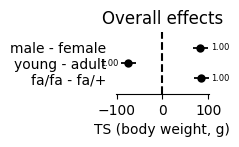

In [25]:
fig, ax = plot_effects(overall_ts, figsize=(1.2, 0.8), title="Overall effects")
fig.savefig(PLOT_DIR / "ts_body_weight_overall.pdf", bbox_inches="tight")

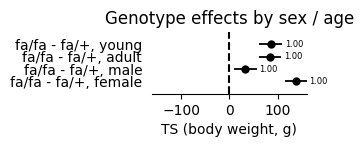

In [15]:
fig, ax = plot_effects(gtyp_ts, figsize=(2, 0.8), title="Genotype effects by sex / age")
# fig.savefig(PLOT_DIR / "ts_body_weight_gtyp_given_sex_age.pdf", bbox_inches="tight")

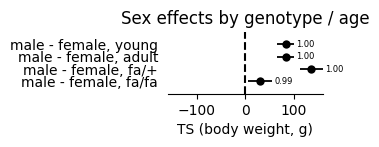

In [16]:
fig, ax = plot_effects(sex_ts, figsize=(2, 0.8), title="Sex effects by genotype / age")
# fig.savefig(PLOT_DIR / "ts_body_weight_sex_given_gtyp_age.pdf", bbox_inches="tight")

## Posterior sign probabilities and significance

In [17]:
def sign_prob_table(ts):
    probs = get_sign_probs(ts)
    return pd.DataFrame({
        "sign_probability": probs,
        "significance": {k: get_signif(v) for k, v in probs.items()},
    })

sp_all = pd.concat(
    [sign_prob_table(overall_ts),
     sign_prob_table(gtyp_ts),
     sign_prob_table(sex_ts)],
    keys=("overall", "gtyp given sex/age", "sex given gtyp/age"),
    names=("contrast", "group"),
)
display(sp_all)
# sp_all.to_csv("../sp_tables/body_weight_contrasts.csv")

sign_probability significance
contrast           group                                              
overall            fa/fa - fa/+                   1.00000            *
                   young - adult                  0.00000            *
                   male - female                  1.00000            *
gtyp given sex/age fa/fa - fa/+, female           1.00000            *
                   fa/fa - fa/+, male             0.99625            *
                   fa/fa - fa/+, adult            1.00000            *
                   fa/fa - fa/+, young            1.00000            *
sex given gtyp/age male - female, fa/fa           0.99350            *
                   male - female, fa/+            1.00000            *
                   male - female, adult           1.00000            *
                   male - female, young           1.00000            *